In [25]:
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, roc_auc_score
from tabpfn import TabPFNClassifier

In [26]:
demo = pd.read_csv("data/training_data/mixed_demographics.csv", index_col=0)
demo_test = pd.read_csv("data/test_samples/test.csv", index_col=0)
y = demo["MI"].map({"healthy": 1, "pMI": 0})

train_files = [f"data/training_data/mixed_samples/{i}{demo.loc[i, 'MI']}.npy" for i in demo.index]
test_files = [f"data/test_samples/test_samples/{i - 900}.npy" for i in demo_test.index]
files = train_files + test_files
y.value_counts()

MI
1    452
0    448
Name: count, dtype: int64

In [35]:
time_frame = 1
tissue = 1
heart = np.load(train_files[1])
heart_slice = heart[time_frame]
heart_slice = pd.DataFrame(heart_slice, columns=["x", "y", "z", "tissue"])
tissue_slice = heart_slice[heart_slice["tissue"] == tissue].drop(columns=["tissue"])
center = tissue_slice.mean()
std = tissue_slice.std()
radius = np.sqrt(((tissue_slice - center) ** 2).sum(axis=1)).mean()
hull = ConvexHull(tissue_slice)
volume = hull.volume
area = hull.area

In [36]:
center

x     1.459687
y    -5.258156
z    48.389506
dtype: float64

In [ ]:
def shape_stats(part):
    tissue = part[["x", "y", "z"]]
    center = tissue.mean()
    std = tissue.std()
    radius = np.sqrt(((tissue - center) ** 2).sum(axis=1))
    hull = ConvexHull(tissue)
    return {
        "cx": center["x"], "cy": center["y"], "cz": center["z"],
        "stdx": std["x"], "stdy": std["y"], "stdz": std["z"],
        "radius": radius.mean(),
        "volume": hull.volume, "area": hull.area,
    }

In [29]:
def heart_features(file):
    heart = np.load(file)
    start = pd.DataFrame(heart[0], columns=["x", "y", "z", "type"])
    prev = start
    rows = []
    for frame in range(10):
        heart_slice = pd.DataFrame(heart[frame], columns=["x", "y", "z", "type"])
        heart_slice["move"] = np.sqrt(((heart_slice[["x", "y", "z"]] - start[["x", "y", "z"]]) ** 2).sum(axis=1))
        heart_slice["speed"] = np.sqrt(((heart_slice[["x", "y", "z"]] - prev[["x", "y", "z"]]) ** 2).sum(axis=1))
        row = {"frame": frame}
        for type in [0, 1, 2]:
            part = heart_slice[heart_slice["type"] == type]
            for name, value in shape_stats(part).items():
                row[f"t{type}_{name}"] = value
            row[f"t{type}_move"] = part["move"].mean()
            row[f"t{type}_speed"] = part["speed"].mean()
        row["thickness"] = row["t1_radius"] - row["t0_radius"]
        row["muscle"] = row["t1_volume"] - row["t0_volume"]
        row["cavity_ratio"] = row["t0_volume"] / row["t1_volume"]
        rows.append(row)
        prev = heart_slice
    return pd.DataFrame(rows)

In [30]:
# frames = []
# for i in range(len(files)):
#     heart_df = heart_features(files[i])
#     heart_df["id"] = i
#     frames.append(heart_df)
#     if (i + 1) % 100 == 0:
#         print(i + 1)

# frames = pd.concat(frames).reset_index(drop=True)
# frames.to_csv("frames.csv", index=False)
frames = pd.read_csv("frames.csv")
frames

,frame,t0_cx,t0_cy,t0_cz,t0_stdx,t0_stdy,t0_stdz,t0_radius,t0_volume,t0_area,...,t2_stdz,t2_radius,t2_volume,t2_area,t2_move,t2_speed,thickness,muscle,cavity_ratio,id
0,0,1.442435,1.311847,51.785079,17.116966,18.270766,32.505776,39.678516,237037.605123,20190.951152,...,34.629533,45.297369,353970.112360,27136.990278,0.000000,0.000000,6.780979,172675.544793,0.578545,0
1,1,1.064598,1.813136,48.671063,15.874132,16.734562,30.184691,36.734967,187018.989874,17267.401980,...,31.898811,41.853664,282809.647724,23310.476165,4.918037,4.918037,6.559916,143203.231438,0.566343,0
2,2,0.999121,0.750947,46.919439,14.452375,15.401601,28.416259,34.123931,149346.070893,14979.164616,...,30.106998,39.099618,227258.830209,20213.749804,9.276856,4.850208,7.117144,137503.232159,0.520643,0
3,3,0.363511,0.276508,44.124517,13.847462,14.652801,26.539186,32.165257,126397.055448,13354.664310,...,27.740721,36.725915,192668.051488,18003.191530,12.581112,3.584951,6.854201,118280.135843,0.516587,0
4,4,1.855917,0.596655,48.457786,14.671644,15.263936,28.735943,34.347992,150649.798960,15129.516606,...,30.293008,40.203297,246931.325291,21279.448397,7.804181,5.115342,7.917412,156844.865506,0.489927,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,5,0.473067,-4.781580,45.359158,14.546114,15.535431,27.722366,33.709617,146044.661443,14710.611802,...,29.287797,39.279083,230566.678871,20246.523293,6.277355,6.127638,7.935497,154108.725637,0.486567,999
9996,6,0.695692,-4.013389,45.909966,15.511089,16.474048,28.964320,35.545743,171877.704616,16293.035150,...,30.439352,40.563854,257281.395528,21838.094701,4.012090,2.536737,6.852645,142844.986006,0.546124,999
9997,7,0.886800,-3.602729,45.562177,15.660065,16.737576,28.923518,35.723801,176528.799155,16526.624736,...,30.060136,40.351680,254063.082504,21658.699493,4.718288,0.978754,6.484584,135314.914589,0.566081,999
9998,8,1.317083,-3.920567,46.468596,15.779929,17.005813,29.251698,36.118311,182867.369349,16934.000310,...,30.318214,40.821365,260528.854138,22044.680970,4.268735,0.738994,6.560044,140298.870054,0.565862,999


In [31]:
wide = frames.pivot(index="id", columns="frame")
wide.columns = [f"{col}_f{frame}" for col, frame in wide.columns]

summary = frames.drop(columns="frame").groupby("id").agg(["mean", "std", "min", "max"])
summary.columns = [f"{col}_{stat}" for col, stat in summary.columns]

max = frames.loc[frames.groupby("id")["t0_volume"].idxmax()].set_index("id")
min = frames.loc[frames.groupby("id")["t0_volume"].idxmin()].set_index("id")
change = max - min
change.columns = [f"{col}_change" for col in change.columns]

cycle = pd.DataFrame(index=max.index)
cycle["ratio_max"] = max["cavity_ratio"]
cycle["ratio_min"] = min["cavity_ratio"]
cycle["thickening"] = (min["thickness"] - max["thickness"]) / max["thickness"]
cycle["max_frame"] = max["frame"]
cycle["min_frame"] = min["frame"]

heart_X = pd.concat([wide, summary, change, cycle], axis=1)
heart_X.shape

(1000, 546)

In [37]:
demo_all = pd.concat([demo.drop(columns=["MI"]), demo_test]).reset_index(drop=True)

X_all = pd.merge(demo_all, heart_X, left_index=True, right_index=True).astype(float)

X = X_all.iloc[:900]
X_test = X_all.iloc[900:]
X.shape, X_test.shape

((900, 553), (100, 553))

In [33]:
import os
os.environ["TABPFN_TOKEN"] = "tabpfn_sk_ndsDjVrsnFthyKfEPmr92wTpUg_Azgdu68BLiNQWL5w"

In [34]:
model = TabPFNClassifier(ignore_pretraining_limits=True, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prob = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
print(f1_score(y, prob >= 0.5))
print(roc_auc_score(y, prob))

0.9544950055493896
0.9928245496207333


In [42]:
from sklearn.ensemble import RandomForestClassifier

model = TabPFNClassifier(ignore_pretraining_limits=True, random_state=42)
model.fit(X, y)

,n_estimators,'auto'
,auto_scale_n_estimators,True
,categorical_features_indices,None
,softmax_temperature,'auto'
,balance_probabilities,False
,average_before_softmax,False
,model_path,'auto'
,device,'auto'
,ignore_pretraining_limits,True
,inference_precision,'auto'
,fit_mode,'fit_preprocessors'


In [11]:
model.fit(X, y)
pred = model.predict(X_test)

submission = pd.DataFrame({"id": demo_test.index - 900, "healthy": pred})
submission.to_csv("submission.csv", index=False)
submission.head(10)

,id,healthy
0,0,0
1,1,1
2,2,1
3,3,1
4,4,0
5,5,0
6,6,1
7,7,0
8,8,1
9,9,0


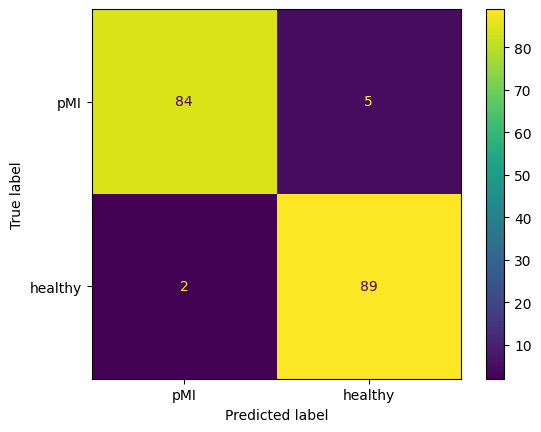

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

_, valid_index = next(cv.split(X, y))

ConfusionMatrixDisplay.from_predictions(
    y.iloc[valid_index], prob[valid_index] >= 0.5,
    labels=[0, 1], display_labels=["pMI", "healthy"],
)
plt.show()

In [13]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prob = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
print(f1_score(y, prob >= 0.5))
print(roc_auc_score(y, prob))

0.8490770901194354
0.9318109987357774


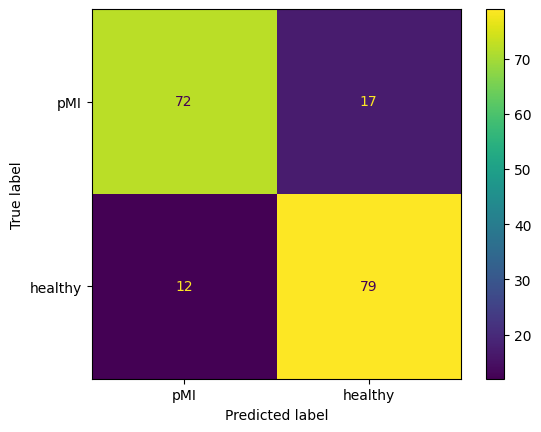

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

_, valid_index = next(cv.split(X, y))

ConfusionMatrixDisplay.from_predictions(
    y.iloc[valid_index], prob[valid_index] >= 0.5,
    labels=[0, 1], display_labels=["pMI", "healthy"],
)
plt.show()
